# Lab 05: Attention Against Recurrence

Uses `lab05_starter.py` unchanged. Chance is 0.25 for recall and 0.50 for the order task. Starter defaults and seeds 0, 1 and 2 unless noted.

In [1]:
import math
import os
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from lab05_starter import (AttentionReadout, OrderClassifier, make_order_batch, make_recall_batch,
                           train_order, train_recall)

SEEDS = [0, 1, 2]
os.makedirs("figures", exist_ok=True)

## Run the starter once

In [2]:
accuracy, _ = train_recall("attention", seq_len=30, seed=0)
print(f"attention readout, 30 steps: {accuracy:.3f}")
accuracies = train_order("sinusoidal", seed=0, steps=300, test_lens=(16,))
print(f"order task, 2 blocks, 300 updates: {accuracies[0]:.3f}")

attention readout, 30 steps: 1.000


order task, 2 blocks, 300 updates: 1.000


Both 1.000 with PyTorch's attention.

## Implement scaled dot-product attention

The mask is boolean and True means "may attend", same as the starter.

In [3]:
def causal_mask(length):
    # row i (the query) may look at columns 0..i (the keys)
    return torch.tril(torch.ones(length, length, dtype=torch.bool))


def scaled_dot_product_attention(q, k, v, mask=None):
    """softmax(q k^T / sqrt(d_k)) v.
    q: (..., T_q, d_k)   k: (..., T_k, d_k)   v: (..., T_k, d_v)
    mask: boolean, broadcastable to (..., T_q, T_k); False entries are blocked.
    Returns (output, weights)."""
    d_k = k.shape[-1]
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)          # (..., T_q, T_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))       # before the softmax
    weights = torch.softmax(scores, dim=-1)                     # over the keys
    row_sums = weights.sum(dim=-1)
    assert torch.allclose(row_sums, torch.ones_like(row_sums), atol=1e-5), "a row of weights doesn't sum to 1"
    if mask is not None:
        assert (weights.masked_select(~mask.expand_as(weights)) == 0).all(), "a masked position got weight"
    return weights @ v, weights

## Compare against PyTorch with and without a causal mask

In [4]:
torch.manual_seed(0)
q, k, v = torch.randn(2, 4, 5, 8), torch.randn(2, 4, 7, 8), torch.randn(2, 4, 7, 8)
mine, _ = scaled_dot_product_attention(q, k, v)
ref = F.scaled_dot_product_attention(q, k, v)
print(f"no mask, 5 queries 7 keys: match {torch.allclose(mine, ref, atol=1e-5)}  max diff {(mine - ref).abs().max():.1e}")

s = torch.randn(2, 4, 6, 8)
mine, weights = scaled_dot_product_attention(s, s, s, mask=causal_mask(6))
ref = F.scaled_dot_product_attention(s, s, s, is_causal=True)
print(f"causal mask, 6 steps:      match {torch.allclose(mine, ref, atol=1e-5)}  max diff {(mine - ref).abs().max():.1e}")
print("largest weight above the diagonal:", weights[..., ~causal_mask(6)].abs().max().item())
print(weights[0, 0].numpy().round(2))

no mask, 5 queries 7 keys: match True  max diff 3.6e-07
causal mask, 6 steps:      match True  max diff 3.6e-07
largest weight above the diagonal: 0.0
[[1.   0.   0.   0.   0.   0.  ]
 [0.01 0.99 0.   0.   0.   0.  ]
 [0.16 0.15 0.7  0.   0.   0.  ]
 [0.07 0.02 0.19 0.73 0.   0.  ]
 [0.01 0.   0.01 0.02 0.96 0.  ]
 [0.08 0.03 0.02 0.06 0.   0.81]]


Both match (max diff 3.6e-07). Weights above the diagonal are exactly 0.

## Implement multi-head attention

In [5]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.d_model, self.n_heads, self.d_head = d_model, n_heads, d_model // n_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)

    def split_heads(self, x):
        batch, length, _ = x.shape
        return x.view(batch, length, self.n_heads, self.d_head).transpose(1, 2)  # (batch, heads, T, d_head)

    def forward(self, x, context=None, mask=None):
        context = x if context is None else context
        q = self.split_heads(self.w_q(x))
        k = self.split_heads(self.w_k(context))
        v = self.split_heads(self.w_v(context))
        out, self.last_weights = scaled_dot_product_attention(q, k, v, mask=mask)
        batch, _, length, _ = out.shape
        out = out.transpose(1, 2).reshape(batch, length, self.d_model)  # concatenate the heads
        return self.w_o(out)

## Copy nn.MultiheadAttention's weights and compare

In [6]:
def copy_from_reference(mine, reference):
    d = mine.d_model
    W, b = reference.in_proj_weight, reference.in_proj_bias  # stacked as query, key, value
    with torch.no_grad():
        for lin, i in ((mine.w_q, 0), (mine.w_k, 1), (mine.w_v, 2)):
            lin.weight.copy_(W[i * d:(i + 1) * d])
            lin.bias.copy_(b[i * d:(i + 1) * d])
        mine.w_o.weight.copy_(reference.out_proj.weight)
        mine.w_o.bias.copy_(reference.out_proj.bias)


mha = MultiHeadAttention(32, 4)
reference = nn.MultiheadAttention(32, 4, batch_first=True)
copy_from_reference(mha, reference)

x = torch.randn(3, 6, 32)
context = torch.randn(3, 9, 32)
cases = {
    "self-attention": (mha(x), reference(x, x, x)[0]),
    # PyTorch's attn_mask is True where blocked, the opposite of mine
    "causal self-attention": (mha(x, mask=causal_mask(6)), reference(x, x, x, attn_mask=~causal_mask(6))[0]),
    "cross-attention, 6 to 9": (mha(x, context=context), reference(x, context, context)[0]),
}
for name, (a, b) in cases.items():
    print(f"{name:<24} match {torch.allclose(a, b, atol=1e-5)}  max diff {(a - b).abs().max():.1e}")

self-attention           match True  max diff 1.8e-07
causal self-attention    match True  max diff 1.8e-07
cross-attention, 6 to 9  match True  max diff 9.1e-08


All three match, including the 9-step context.

## Check the comparison catches the three silent mistakes

In [7]:
def softmax_wrong_axis(q, k, v, mask=None):
    scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    return torch.softmax(scores, dim=-2) @ v


def mask_after_softmax(q, k, v, mask=None):
    weights = torch.softmax(q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1]), dim=-1)
    return (weights * mask if mask is not None else weights) @ v


class WrongSplit(MultiHeadAttention):
    def split_heads(self, x):
        batch, length, _ = x.shape
        return x.view(batch, self.n_heads, length, self.d_head)  # same shape, wrong order


ref = F.scaled_dot_product_attention(s, s, s, is_causal=True)
print("softmax over the queries:", torch.allclose(softmax_wrong_axis(s, s, s, causal_mask(6)), ref, atol=1e-5))
print("mask after the softmax:  ", torch.allclose(mask_after_softmax(s, s, s, causal_mask(6)), ref, atol=1e-5))
wrong = WrongSplit(32, 4)
copy_from_reference(wrong, reference)
print("heads split in the wrong order:", torch.allclose(wrong(x), reference(x, x, x)[0], atol=1e-5))

softmax over the queries: False
mask after the softmax:   False
heads split in the wrong order: False


All three fail the comparison.

## Count parameters for 1, 2, 4 and 8 heads

In [8]:
count = lambda m: sum(p.numel() for p in m.parameters())
for h in (1, 2, 4, 8):
    print(f"{h} heads: {count(MultiHeadAttention(32, h))} parameters")

1 heads: 4224 parameters
2 heads: 4224 parameters
4 heads: 4224 parameters
8 heads: 4224 parameters


4224 every time, because the heads split the same four 32 x 32 projections instead of adding new ones.

## Shuffle the input and compare the output

In [9]:
perm = torch.randperm(6)
print("permutation:", perm.tolist())
print("layer(shuffled x) == shuffled layer(x):", torch.allclose(mha(x[:, perm]), mha(x)[:, perm], atol=1e-6))
print("layer(shuffled x) == layer(x):         ", torch.allclose(mha(x[:, perm]), mha(x), atol=1e-6))

permutation: [0, 1, 5, 4, 3, 2]
layer(shuffled x) == shuffled layer(x): True
layer(shuffled x) == layer(x):          False


The output is shuffled the same way, and it isn't equal to the unshuffled output.

## Compare the attention readout with an LSTM on recall

LSTM with forget bias 3. Both use the starter defaults.

In [10]:
def print_row(name, accs):
    seeds = "  ".join(f"{a:.3f}" for a in accs)
    print(f"{name:<22} {seeds}   mean {sum(accs) / len(accs):.3f}")


recall = {}
for seq_len in [30, 100, 400]:
    print(f"{'length ' + str(seq_len):<22} seed0  seed1  seed2")
    for kind in ["attention", "lstm"]:
        recall[(kind, seq_len)] = [train_recall(kind, seq_len, seed=s, attention_fn=scaled_dot_product_attention)
                                   for s in SEEDS]
        print_row(kind, [acc for acc, _ in recall[(kind, seq_len)]])
    print_row("weight on step 0", [w for _, w in recall[("attention", seq_len)]])
    print()

length 30              seed0  seed1  seed2


attention              1.000  1.000  1.000   mean 1.000


lstm                   1.000  1.000  1.000   mean 1.000
weight on step 0       0.730  0.742  0.674   mean 0.716

length 100             seed0  seed1  seed2


attention              1.000  1.000  1.000   mean 1.000


lstm                   0.252  1.000  0.504   mean 0.585
weight on step 0       0.738  0.746  0.658   mean 0.714

length 400             seed0  seed1  seed2


attention              1.000  1.000  1.000   mean 1.000


lstm                   0.245  0.244  0.245   mean 0.245
weight on step 0       0.741  0.746  0.663   mean 0.717



Attention gets 1.000 on every seed at every length. The LSTM gets 1.000 at 30, 0.252, 1.000 and 0.504 at 100, and chance at 400.

The weight on step 0 stays between 0.66 and 0.75 at all three lengths.

## Investigate weight spread and update the label position

Seed 0, length 100. `train_readout` is the starter's loop returning the model. Then the label is swapped with a random step in each validation sequence.

In [11]:
def train_readout(seq_len, seed, steps=600):
    # same loop as train_recall in the starter, but returns the model
    torch.manual_seed(seed)
    generator = torch.Generator().manual_seed(seed + 100)
    model = AttentionReadout(scaled_dot_product_attention)
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
    for _ in range(steps):
        x, y = make_recall_batch(64, seq_len, generator)
        loss = F.cross_entropy(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
    return model


readout = train_readout(100, seed=0)
x_val, y_val = make_recall_batch(1000, 100, torch.Generator().manual_seed(999))
rows = torch.arange(1000)
with torch.no_grad():
    acc = (readout(x_val).argmax(1) == y_val).float().mean().item()
    w = readout.last_weights[:, 0]
    print(f"accuracy {acc:.3f}  weight on step 0 {w[:, 0].mean():.3f}  "
          f"largest weight on any other step {w[:, 1:].max():.4f}")

    where = torch.randint(0, 100, (1000,), generator=torch.Generator().manual_seed(5))
    moved = x_val.clone()
    moved[rows, 0], moved[rows, where] = x_val[rows, where], x_val[rows, 0]
    acc = (readout(moved).argmax(1) == y_val).float().mean().item()
    print(f"label moved to a random step: accuracy {acc:.3f}  "
          f"weight on its new step {readout.last_weights[rows, 0, where].mean():.3f}")

accuracy 1.000  weight on step 0 0.738  largest weight on any other step 0.0032
label moved to a random step: accuracy 1.000  weight on its new step 0.738


Step 0 gets 0.738 and no other step gets more than 0.0032. With the label moved, accuracy stays 1.000 and the same 0.738 follows it to the new step. The readout picks the step by its content, not its position.

The LSTM classifies from its last hidden state only, so the label has to make it through every step after it.

What this doesn't show: attention handling long-range dependencies in general. The label here can be found without knowing where it is.

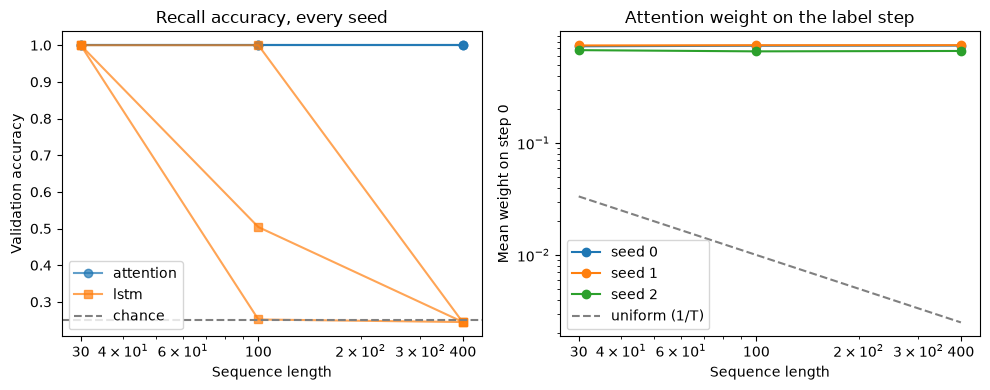

In [12]:
lengths = [30, 100, 400]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for kind, marker in [("attention", "o"), ("lstm", "s")]:
    for i, seed in enumerate(SEEDS):
        accs = [recall[(kind, T)][i][0] for T in lengths]
        axes[0].plot(lengths, accs, marker=marker, alpha=0.7,
                     color="C0" if kind == "attention" else "C1", label=kind if i == 0 else None)
axes[0].axhline(0.25, color="gray", linestyle="--", label="chance")
axes[0].set_xscale("log")
axes[0].set_xticks(lengths, [str(T) for T in lengths])
axes[0].set_xlabel("Sequence length")
axes[0].set_ylabel("Validation accuracy")
axes[0].set_title("Recall accuracy, every seed")
axes[0].legend()

for i, seed in enumerate(SEEDS):
    axes[1].plot(lengths, [recall[("attention", T)][i][1] for T in lengths], marker="o", label=f"seed {seed}")
axes[1].plot(lengths, [1 / T for T in lengths], color="gray", linestyle="--", label="uniform (1/T)")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xticks(lengths, [str(T) for T in lengths])
axes[1].set_xlabel("Sequence length")
axes[1].set_ylabel("Mean weight on step 0")
axes[1].set_title("Attention weight on the label step")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/recall_vs_length.png", dpi=150)
plt.show()